
#  NUMPY


La libreria NumPy, nome derivante dalla crasi tra *Num*erical *Py*thon, è il pilastro fondamentale per il calcolo scientifico e l'analisi dati in Python.

Nella pratica, NumPy è uno standard de facto: le sue strutture dati sono utilizzate come base (o "motore" interno) da quasi tutte le altre librerie di Data Science e Machine Learning.



E' fondamentale installare le librerie esterne all'interno del nostro ambiente virtuale isolato.

Apriamo il terminale e usiamo pip:

In [ ]:
pip install numpy # da terminale

%pip install numpy #qui


La convenzione universale per importare NumPy nei nostri script è utilizzare l'alias np:

In [3]:
import numpy as np # importing convention

# Arrays

Il cuore pulsante di NumPy è l'oggetto ndarray (n-dimensional array). Si tratta di una struttura dati ottimizzata per rappresentare vettori, matrici e tensori a 
n dimensioni, contenenti dati di tipo strettamente omogeneo (tutti numeri interi, o tutti decimali, ecc.  **all of the same type**,). All standard data types are available

Il metodo più semplice per creare un array è usare il costruttore np.array() passandogli una normale lista Python:

In [3]:
a = np.array([1, 2, 3, 4, 5])
type(a)

numpy.ndarray

## Array vs Liste: Perché usare NumPy? ##
A prima vista, un array 1D di NumPy può sembrare identico a una lista Python. Tuttavia, dal punto di vista ingegneristico, sono mondi completamente diversi.

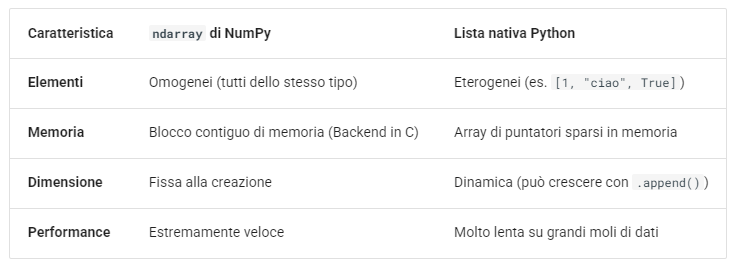

### Il segreto delle performance:
Le liste Python sono flessibili ma pesanti. Poiché una lista può contenere tipi di dati misti, Python deve controllare il tipo di ogni singolo elemento prima di eseguire un'operazione.
In NumPy, essendo l'array omogeneo, i dati sono salvati nella RAM in blocchi fisicamente contigui. Le operazioni matematiche vengono eseguite direttamente al livello del processore da codice scritto in C o C++ super ottimizzato, bypassando completamente le lentezze dell'interprete Python.

### Vettorizzazione (Vectorization)
Gli array NumPy sono progettati specificamente per l'algebra lineare. Facciamo un esempio pratico: vogliamo moltiplicare due vettori (array 1D) elemento per elemento.

Se usassimo le normali liste Python, dovremmo ricorrere a un ciclo for:

In [38]:
# Approccio standard Python (Lento)
a = [1, 2, 3]
b = [4, 5, 6]
c =[]

for i in range(len(a)):
    c.append(a[i] * b[i])

Se estendessimo il calcolo a un'immagine a colori (che è un array 3D: altezza, larghezza, canali RGB), avremmo bisogno di ben tre cicli for annidati! In Python, i cicli annidati su milioni di elementi richiedono secondi, se non minuti.

In NumPy, possiamo sfruttare la Vettorizzazione. Possiamo applicare l'operazione matematica direttamente all'intero oggetto array:

In [ ]:
# Approccio NumPy (Vettorizzato e Veloce)
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

c = a * b  # Risultato: array([4, 10, 18])

Questa sintassi, oltre ad essere infinitamente più leggibile (sembra vera e propria matematica scritta su carta), è ordini di grandezza più veloce. Il ciclo for avviene ancora, ma avviene "sotto il cofano" nel backend in C di NumPy, non in Python.

Questa è la regola d'oro del calcolo scientifico in Python: evitare i cicli for ogni volta che è possibile ed esprimerli come operazioni su array NumPy.

## Creazione di un Array
Il metodo più immediato per creare un array è l'uso del costruttore np.array() a cui passare una lista Python:

In [6]:
a = np.array([1, 2, 3, 4, 5, 6])
print(a)

[1 2 3 4 5 6]


Passando una lista di liste, otteniamo un array bidimensionale (una matrice):

In [ ]:
b = np.array([[1, 2, 3], [4, 5, 6]])
print(b)

### Upcasting (Conversione automatica)
A differenza delle liste, gli array NumPy devono contenere dati omogenei. Cosa succede se passiamo una lista con tipi misti, come un intero e un decimale?

In [ ]:
d = np.array([1, 3.14])

NumPy applica il principio dell'upcasting: converte automaticamente tutti gli elementi al tipo di dato più "capiente" per evitare perdita di informazioni. In questo caso, l'intero 1 è diventato il float 1.0.

Se mescoliamo numeri e stringhe, tutto diventerà una stringa:

In [ ]:
e = np.array([1, "python"])

### Tipi di dato (dtype)
A differenza del normale Python (che ha solo int e float), NumPy fornisce un controllo granulare sulla memoria, mettendoci a disposizione tipi di dato derivati direttamente dal linguaggio C.
Questo è cruciale nel Data Science: elaborare un milione di numeri a 64-bit richiede il doppio della RAM rispetto a elaborarli a 32-bit.

I tipi a dimensione fissa (sized aliases) più utilizzati sono:
- np.int8, np.int16, np.int32, np.int64: Interi con segno a 8, 16, 32 o 64 bit.
- np.float32,np.float64: Numeri a virgola mobile (decimali). In ambito Machine/Deep Learning, il float32 è lo standard assoluto per risparmiare memoria sulle GPU.

Possiamo specificare il tipo di dato esplicitamente al momento della creazione dell'array usando il parametro dtype:

In [5]:
# type can be set
a = np.array([1, 2, 3], dtype='float64')
print (a.dtype,'\n')

#oppure
a=np.array([1, 2, 3], 'float64')
print (a,a.dtype,'\n')

a=np.array([1, 2, 3],'uint32')
print (a,a.dtype)

float64 

[1. 2. 3.] float64 

[1 2 3] uint32


In [ ]:
# or inferred: 
a=np.array([1, 2, 3.3])
print (a,a.dtype,'\n')

In [ ]:
# complex
a=np.array([1+2j, 3+4j, 5+6*1j])
print (a,a.dtype,'\n')

In [ ]:
# bool
a = np.array([True, False, False, True])
print (a,a.dtype,'\n')

# string
a=np.array(['bonjour messieurs dames', 'Hello', 'Hallo'])
print (a,a.dtype,'\n')

### Ispezionare un Array (Shape, Ndim, Size)
Quando lavoriamo con dataset complessi (es. batch di immagini), è fondamentale conoscere la geometria dei nostri dati. NumPy offre tre attributi fondamentali:

Arrays are memory-efficient container that provides fast numerical operations

In [ ]:
matrice = np.array([[1, 2, 3],[4, 5, 6]])

matrice.ndim  # Numero di dimensioni (Assi)

matrice.shape # La forma: (righe, colonne)

matrice.size  # Numero totale di elementi (2 * 3)

## Altri metodi di creazione
Oltre a convertire liste esistenti, NumPy offre funzioni ottimizzate per generare array da zero (utilissime per preallocare memoria o creare dati fittizi).

### Zeri e Uni 

In [ ]:
z = np.zeros((3, 3)) # Array 3x3 riempito di zeri

u = np.ones((2, 4)) # Array 2x4 riempito di uni

[[2.12199579e-314 1.48751905e-311]
 [8.87341900e-321 3.79442416e-321]]


### Generazione di sequenze (arange e linspace)
In Data Science, queste due funzioni sono onnipresenti per generare assi temporali o griglie di coordinate:

In [ ]:
# Come il range() di Python, ma genera un array e accetta numeri decimali
np.arange(0, 10, 2)  # (start, stop_escluso, step)

# Genera N numeri equamente distanziati tra due estremi
np.linspace(0, 1, 5) # (start, stop_incluso, numero_di_elementi)

## Accesso agli elementi (Indexing)

In Python standard, per accedere a una lista di liste scriveremmo lista[0][1]. In NumPy, questa sintassi è un grave errore di performance perché forza la creazione in memoria di un array temporaneo per la prima riga prima di estrarre la colonna.

La sintassi corretta, veloce e "NumPy-onica" utilizza la virgola per separare le dimensioni: array[riga, colonna].

In [11]:
b = np.array([[10, 20, 30],[40, 50, 60]])

# Voglio l'elemento alla prima riga (indice 0) e seconda colonna (indice 1)
b[0, 1]

20

### Slicing Multi-dimensionale
Lo slicing in NumPy (start:stop:step) è potentissimo perché agisce simultaneamente su più dimensioni. È la tecnica alla base del ritaglio di immagini (cropping) nella Computer Vision.

In [10]:
l = [0, 1, 2, 3]
a = np.array(l)
print (a.tolist(), type(a.tolist()))

[0, 1, 2, 3] <class 'list'>


In [ ]:
b = np.array([[1, 2, 3],[4, 5, 6],[7, 8, 9]])

# Voglio le prime due righe (0:2), ma solo le ultime due colonne (1:)
b[0:2, 1:] # l'indice di inizio è incluso, l'indice di fine è escluso

# Voglio TUTTE le righe (:), ma solo la colonna centrale (1)
b[:, 1]

## Maschere Booleane (Masking)
Possiamo estrarre sottoinsiemi di dati applicando condizioni logiche. Questo processo crea una "maschera" di True e False.

In [16]:
b = np.array([1, 2, 3, 4, 5, 6])

# Quali elementi sono maggiori di 3?
mask = b > 3
print (mask)
# Applichiamo la maschera per estrarre i dati
b[mask]
print(b[mask])

# Forma compatta
b[b > 3]


[False False False  True  True  True]
[4 5 6]


array([4, 5, 6])

## Sostituzione condizionale: np.where
Spesso non vogliamo solo estrarre dati, ma modificarli in base a una condizione (es. "imposta a 0 tutti i valori negativi"). La funzione np.where(condizione, valore_se_vero, valore_se_falso) è la soluzione standard:

In [ ]:
x = np.array([-2, 5, -1, 8])
np.where(x < 0, 0, x)

## Operazioni fondamentali sugli array
Dopo aver visto come creare e ispezionare gli array, passiamo ora alle operazioni fondamentali. La potenza di NumPy risiede nella capacità di eseguire calcoli complessi su enormi moli di dati senza scrivere un singolo ciclo for.

### Operazioni algebriche (Element-wise)
Tutti i normali operatori matematici in Python (+, -, *, /, **) applicati agli array NumPy vengono eseguiti elemento per elemento (element-wise).

In [ ]:
a = np.array([10, 20, 30])
b = np.array([1, 2, 3])

a + b

a - b

a / b


# Cosa succede se sommiamo un array con un singolo numero (scalare)?
a + 100
# array([110, 120, 130])
# NumPy propaga (effettua il broadcasting) automaticamente il numero 100 su tutti gli elementi dell'array, evitandoci di dover creare un array di soli 100 delle stesse dimensioni di a.

#### Moltiplicazione * vs Moltiplicazione Matriciale

Se avete un background matematico o venite da MATLAB, fate molta attenzione: in NumPy, a * b calcola il prodotto elemento per elemento (Prodotto di Hadamard), NON il prodotto riga per colonna delle matrici. Per quello esiste un operatore apposito: @ oppure metodo .dot

In [ ]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

C = A @ B

A.dot(B)

## Aggregazioni e l'enigma del parametro axis
NumPy offre metodi ultra-veloci per calcolare statistiche di base: .sum(), .mean(), .max(), .min().

In [ ]:
a = np.array([1, 2, 3, 4])
a.sum()

Quando lavoriamo con matrici a più dimensioni, possiamo specificare il parametro axis per decidere lungo quale direzione effettuare l'operazione. Questo concetto spesso confonde i principianti:

- axis=0: Muoviti lungo l'asse 0 (le righe) e collassale. Il risultato sarà un'operazione fatta in verticale (per ogni colonna).
- axis=1: Muoviti lungo l'asse 1 (le colonne) e collassale. Il risultato sarà un'operazione fatta in orizzontale (per ogni riga).

In [ ]:
matrice = np.array([[1, 2, 3],[4, 5, 6]])

# Collassa le righe (somma in verticale colonna per colonna)
matrice.sum(axis=0)

# Collassa le colonne (somma in orizzontale riga per riga)
matrice.sum(axis=1)

## Modificare la forma
Spesso abbiamo i dati giusti, ma nella "forma" sbagliata. Ad esempio, potremmo avere un vettore 1D di 16 pixel, ma sapere che rappresenta un'immagine 4x4. La funzione reshape() riorganizza i dati senza alterarli.

In [ ]:
vettore = np.arange(1, 17) # Array da 1 a 16
matrice = vettore.reshape((4, 4)) # voglio 4 righe e 4 colonne 
matrice

# Trucco del -1
vettore.reshape(2, -1) # "Voglio 2 righe, calcola tu quante colonne servono"

L'operazione inversa al reshape è il "flattening", ovvero prendere una matrice N-dimensionale e schiacciarla in un vettore 1D. Ci sono due metodi:

In [ ]:
# Metodo 1: flatten() restituisce una COPIA (più sicuro, consuma più RAM)
matrice.flatten()

# Metodo 2: ravel() restituisce una VISTA (più veloce, ma se modifichi l'output, modifichi anche la matrice originale!)
matrice.ravel()

Copies and views:

In [12]:
a=np.array([1,2,3])
b=a # a view
c=a.copy() # a copy
a[0]=7
print (a,b,c)

[7 2 3] [7 2 3] [1 2 3]


### Concatenazione di Array
Per unire due o più array, si usa np.concatenate(), specificando l'asse lungo il quale effettuare l'unione:

In [ ]:
x = np.array([[1, 2]])
y = np.array([[3, 4]])

# Concatenazione verticale (axis=0)
np.concatenate((x, y), axis=0)

# Concatenazione orizzontale (axis=1)
np.concatenate((x, y), axis=1)

Per comodità e leggibilità, NumPy offre anche np.vstack((x, y)) (concatenazione Verticale) e np.hstack((x, y)) (concatenazione Orizzontale) che fanno esattamente la stessa cosa ma sono più immediate da leggere.

## Inserimento, Rimozione e Aggiunta (Anti-Pattern)
NumPy offre le funzioni np.insert(), np.delete() e np.append() per aggiungere o rimuovere elementi da un array.

In [ ]:
arr = np.array([1, 2, 3])
np.append(arr, [4, 5])


In [4]:
# evenly spaced:
print (np.arange(1,9,2)) # same as "range": start, end (exclusive), step

[1 3 5 7]


In [ ]:
# or by number of points:
print (np.linspace(0, 1, 5)) # start, end, num-points (to be used for plotting f(x))

In [6]:
# 3x3 unitary matrix
# unity3d = np.identity(3)
unity3d = np.eye(2)
print (unity3d,'\n')

[[1. 0.]
 [0. 1.]] 



In [7]:
# generic diagonal matrix
diagonal = np.diag(np.array([1, 20, 3, 4]))
print (diagonal,'\n')

[[ 1  0  0  0]
 [ 0 20  0  0]
 [ 0  0  3  0]
 [ 0  0  0  4]] 



In [8]:
# from lists
array = np.array([(i,j) for i in range(2) for j in range(3)])
print (array,'\n')

[[0 0]
 [0 1]
 [0 2]
 [1 0]
 [1 1]
 [1 2]] 



In [9]:
array.shape

(6, 2)

In [10]:
len(array)

6

## Reshaping

In [13]:
a=np.arange(0,6)
a

array([0, 1, 2, 3, 4, 5])

In [14]:
m=a.reshape(2, 3) 
print ("original=", a,'\n')
print ("3x2 matrix:",'\n', m,'\n')
# is m a view or a copy??

original= [0 1 2 3 4 5] 

3x2 matrix: 
 [[0 1 2]
 [3 4 5]] 



In [15]:
a_from_m = m.flatten()
print ("flattening it out (back to original)=", a_from_m,'\n')

flattening it out (back to original)= [0 1 2 3 4 5] 



In [16]:
# 1D concatenation
a = np.array([1,2])
b = np.array([3,4,5,6])
c = np.array([7,8,9])
print ("1D concatenation:", np.concatenate((a, c, b)),'\n')

1D concatenation: [1 2 7 8 9 3 4 5 6] 



In [17]:
# nD concatenation
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7,8]])
# if no axis is defined, concatenations occurs on the 1st dimension
print ("default 2D concatenation:",'\n', np.concatenate((a,b)),'\n')
print ("concatenation along the first axis:",'\n',np.concatenate((a,b), axis=0),'\n')
print ("concatenation along the second axis:",'\n',np.concatenate((a,b), axis=1),'\n')

default 2D concatenation: 
 [[1 2]
 [3 4]
 [5 6]
 [7 8]] 

concatenation along the first axis: 
 [[1 2]
 [3 4]
 [5 6]
 [7 8]] 

concatenation along the second axis: 
 [[1 2 5 6]
 [3 4 7 8]] 



In [18]:
# adding a dimension, useful for linear algebra
a = np.array([1,2,3]) # Crea un array unidimensionale (1D) con 3 elementi.
# La sua forma (shape) in NumPy è (3,). Non è né una riga né una colonna in senso bidimensionale, ma un semplice vettore di 3 elementi.

# np.newaxis inserisce una nuova dimensione (un nuovo asse) nella posizione in cui viene inserito.
# In questo caso, si trova dopo la virgola (sulle colonne).
print (a[:,np.newaxis]) # Nuova forma (shape): Diventa (3, 1).
# Risultato stampato: Diventa una matrice 2D con 3 righe e 1 colonna (un vettore colonna)       

# trasforma in vettore riga 
# inserisce il nuovo asse prima della virgola (sulle righe).
print (a[np.newaxis,:]) # Nuova forma (shape): Diventa (1, 3).
# Risultato stampato: Diventa una matrice 2D con 1 riga e 3 colonne (un vettore riga)

[[1]
 [2]
 [3]]
[[1 2 3]]


## Indexing and slicing

The items of an array can be accessed and assigned to the same way as other Python sequences (e.g. lists):

In [19]:
a = np.arange(10, 20)
print(a)
print (a[0], a[2], a[-1])

# reminder: the [start:stop:step] works as well. 
# step can be negative and a reverse sequence is thus obtained
print (a[2:9:3])
print (a[::-1])


[10 11 12 13 14 15 16 17 18 19]
10 12 19
[12 15 18]
[19 18 17 16 15 14 13 12 11 10]


In [20]:
a = np.diag(np.arange(3)) 
# np.arange(3) genera il vettore unidimensionale [0, 1, 2].
# np.diag(...) prende questo vettore e lo trasforma in una matrice diagonale 3x3.
print (a,'\n')

#specifichiamo 2 indici
print (a[2,2],'\n') # accede all'elemento riga indice 2 (3 riga) e colonna indice 2 

#specifichiamo 1 indice
# selezione di una riga intera
print (a[2],'\n') # numpy seleziona l'intera riga di quell'indice

# selezione di una colonna intera
print (a[:, 2]) # La notazione : (due punti) significa "seleziona tutte le righe", 
# mentre il , 2 significa "seleziona solo la colonna con indice 2".
# Cosa stampa: La terza colonna, restituita sotto forma di vettore unidimensionale: [0 0 2].

# NB: In Python, tutti gli array 1D vengono stampati in orizzontale per comodità di lettura, dando l'impressione visiva di essere una riga. Ma in realtà, dal punto di vista matematico di NumPy, un array 1D non è né una riga né una colonna: è solo una sequenza di numeri.

# se vuoi preservare righe: colonna_2d = a[:, 2:3]

[[0 0 0]
 [0 1 0]
 [0 0 2]] 

2 

[0 0 2] 

[0 0 2]


In [21]:

# assignment --> modificare valore in una matrice
a[2, 1] = 100 # third line, second column
print (a,'\n')

print(a[1:3, 1]) 
# 3 escluso--> quindi prendere riga 2 e 3
# solo 2 colonna 
# nell output ci sono 2spazi davanti a 1 perche numpy regola la visualizzazione in base
# alla dimensione max che e 100 (quindi 3 spazi)

print(a[1]) # intera riga di indice 1

[[  0   0   0]
 [  0   1   0]
 [  0 100   2]] 

[  1 100]
[0 1 0]


## Fancy indexing (Indicizzazione avanzata)

Gli array NumPy possono essere indicizzati non solo tramite slicing, ma anche utilizzando array di booleani o di interi (chiamati maschere). Questo metodo prende il nome di *fancy indexing*. A differenza dello slicing classico, questo approccio crea delle copie dei dati e non delle semplici viste (*views*).

In [22]:
a = np.random.randint(0, 21, 15) #15 elementi
print ("original array:", a,'\n')

#a % 3 calcola il resto della divisione per 3 per ogni numero nell'array.
#== 0 verifica se il resto è uguale a zero (cioè se il numero è divisibile per 3 o multiplo di 3).
mask = (a % 3 == 0)
print ("the mask:", mask,'\n')

original array: [10 10  1 17  4 12 13 15  2  9 13 10  7 11 15] 

the mask: [False False False False False  True False  True False  True False False
 False False  True] 



In [23]:
filtered_a = a[mask]
# equivalent to a[a%3==0]
print ("the filtered array:", filtered_a,'\n')

the filtered array: [12 15  9 15] 



In [24]:
# Indexing with a mask can be very useful to assign a new value to a sub-array:
print(a)
a[a % 3 == 0] = -1
print ("the modified array:", a,'\n')

[10 10  1 17  4 12 13 15  2  9 13 10  7 11 15]
the modified array: [10 10  1 17  4 -1 13 -1  2 -1 13 10  7 11 -1] 



L'indicizzazione può essere eseguita tramite un array di interi, in cui lo stesso indice può essere ripetuto più volte. Fai attenzione alla notazione!

In [25]:
a = np.arange(0, 100, 10)
print(a)
l = [2, 3, 2, 4, 2] #a python list
print ("selection of indexes: ", a[l],'\n')  #note: [2, 3, 2, 4, 2] is a Python list


[ 0 10 20 30 40 50 60 70 80 90]
selection of indexes:  [20 30 20 40 20] 



Quando viene creato un nuovo array tramite indicizzazione con un array di interi, il nuovo array assume la stessa forma (shape) dell'array di interi:

In [26]:
a=np.arange(0,20,2)
print(a)
idx = np.array([[3,4],[9,7]])
print(idx) # note the shape and the ordering
print (a[idx])

[ 0  2  4  6  8 10 12 14 16 18]
[[3 4]
 [9 7]]
[[ 6  8]
 [18 14]]


## Elementwise operations

### Basic operations

In [27]:
# operations with scalars
a=np.arange(4)
print(a)
print (a+5,'\n')
print (2**a,'\n')

[0 1 2 3]
[5 6 7 8] 

[1 2 4 8] 



### Other operations

comparisons, logical, functions 

In [30]:
# elementwise
print ('equal?:',np.array([1,3,2,5])==np.array([3,1,2,1]))
print ('greater than?:',np.array([1,3,2,5])>np.array([3,1,2,1]))

# array-wise
# La funzione np.array_equal() serve a verificare se due array NumPy sono completamente identici.
np.array_equal(np.array([1,3,2,5]),np.array([3,1,2,1]))

equal?: [False False  True False]
greater than?: [False  True False  True]


False

In [31]:
# logical
a=np.array([1,1,0,0],bool)
b=np.array([1,0,1,0],bool)
print ("logical or:", np.logical_or(a,b))
print ("logical and:", np.logical_and(a,b))

logical or: [ True  True  True False]
logical and: [ True False False False]


In [32]:
# functions
a=np.arange(1,9)
print ("sin:", np.sin(a))
print ("log:", np.log(a))

# works in whatever dimension
m=a.reshape(2,4)
print (m)
print ("exp:", np.exp(m))

sin: [ 0.84147098  0.90929743  0.14112001 -0.7568025  -0.95892427 -0.2794155
  0.6569866   0.98935825]
log: [0.         0.69314718 1.09861229 1.38629436 1.60943791 1.79175947
 1.94591015 2.07944154]
[[1 2 3 4]
 [5 6 7 8]]
exp: [[2.71828183e+00 7.38905610e+00 2.00855369e+01 5.45981500e+01]
 [1.48413159e+02 4.03428793e+02 1.09663316e+03 2.98095799e+03]]


In [33]:
# extracting off-diagonal terms
a= np.tril(np.arange(16).reshape(4,4), -1) # play with the last parameter!
#a= np.triu(np.arange(16).reshape(4,4), -1) # play with the last parameter (sign and value)!
print ("a:", '\n', a , '\n')

print ("transpose:", '\n', a.T , '\n') #a.T is a view!

a: 
 [[ 0  0  0  0]
 [ 4  0  0  0]
 [ 8  9  0  0]
 [12 13 14  0]] 

transpose: 
 [[ 0  4  8 12]
 [ 0  0  9 13]
 [ 0  0  0 14]
 [ 0  0  0  0]] 



N.B.: a linear algebra package exists in numpy, `numpy.linalg`, but performance-wise the scipy one, `scipy.linalg`, is way better, we will see that later